In [18]:
# Data Handling
import pandas as pd
import io
from google.colab import files

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.inspection import permutation_importance
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

print("Libraries imported successfully.")

Libraries imported successfully.


In [19]:
# Upload the CSV file
uploaded = files.upload()

# Load the dataset into a pandas DataFrame
filename = list(uploaded.keys())[0]
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print(f"Successfully loaded {filename}")

Saving synthetic_personal_finance_dataset.csv to synthetic_personal_finance_dataset (1).csv
Successfully loaded synthetic_personal_finance_dataset (1).csv


Input the dataset (Personal Finance ML Dataset on Kaggle) so that the program has data to work with.

In [20]:
print("--- First 5 Rows ---")
display(df.head())

print(f"\nDataset Shape: {df.shape}")

print("\n--- Missing Values per Column ---")
print(df.isnull().sum())

print(f"\nDuplicate Rows: {df.duplicated().sum()}")

print("\n--- Summary Statistics ---")
display(df.describe())

--- First 5 Rows ---


,user_id,age,gender,education_level,employment_status,job_title,monthly_income_usd,monthly_expenses_usd,savings_usd,has_loan,loan_type,loan_amount_usd,loan_term_months,monthly_emi_usd,loan_interest_rate_pct,debt_to_income_ratio,credit_score,savings_to_income_ratio,region,record_date
0,U00001,56,Female,High School,Self-employed,Salesperson,3531.69,1182.59,367655.03,No,NaN,0.00,0,0.00,0.00,0.00,430,8.68,Other,2024-01-09
1,U00002,19,Female,PhD,Employed,Salesperson,3531.73,2367.99,260869.10,Yes,Education,146323.34,36,4953.50,13.33,1.40,543,6.16,North America,2022-02-13
2,U00003,20,Female,Master,Employed,Teacher,2799.49,1003.91,230921.21,No,NaN,0.00,0,0.00,0.00,0.00,754,6.87,Africa,2022-05-12
3,U00004,25,Male,PhD,Employed,Manager,5894.88,4440.12,304815.51,Yes,Business,93242.37,24,4926.57,23.93,0.84,461,4.31,Europe,2023-10-02
4,U00005,53,Female,PhD,Employed,Student,5128.93,4137.61,461509.48,No,NaN,0.00,0,0.00,0.00,0.00,516,7.50,Africa,2021-08-07



Dataset Shape: (32424, 20)

--- Missing Values per Column ---
user_id                        0
age                            0
gender                         0
education_level                0
employment_status              0
job_title                      0
monthly_income_usd             0
monthly_expenses_usd           0
savings_usd                    0
has_loan                       0
loan_type                  19429
loan_amount_usd                0
loan_term_months               0
monthly_emi_usd                0
loan_interest_rate_pct         0
debt_to_income_ratio           0
credit_score                   0
savings_to_income_ratio        0
region                         0
record_date                    0
dtype: int64

Duplicate Rows: 0

--- Summary Statistics ---


,age,monthly_income_usd,monthly_expenses_usd,savings_usd,loan_amount_usd,loan_term_months,monthly_emi_usd,loan_interest_rate_pct,debt_to_income_ratio,credit_score,savings_to_income_ratio
count,32424.000000,32424.000000,32424.000000,3.242400e+04,32424.000000,32424.000000,32424.000000,32424.000000,32424.000000,32424.000000,32424.000000
mean,43.415865,4027.863185,2419.444709,2.437520e+05,100114.735992,58.500000,3092.992339,6.616332,1.194881,575.260424,5.045431
std,14.978246,1916.773353,1388.893084,1.915772e+05,152536.588635,104.865373,6478.939776,9.472964,3.761964,159.023227,2.851344
min,18.000000,500.000000,150.010000,6.359600e+02,0.000000,0.000000,0.000000,0.000000,0.000000,300.000000,0.100000
25%,30.000000,2657.795000,1397.497500,8.629155e+04,0.000000,0.000000,0.000000,0.000000,0.000000,437.000000,2.580000
50%,43.000000,3997.740000,2219.575000,2.017003e+05,0.000000,0.000000,0.000000,0.000000,0.000000,575.000000,5.040000
75%,56.000000,5351.607500,3254.037500,3.589662e+05,189499.070000,60.000000,3574.567500,13.140000,0.920000,714.000000,7.510000
max,69.000000,12404.050000,10082.710000,1.237774e+06,499954.750000,360.000000,47723.840000,30.000000,90.670000,850.000000,10.000000


In [21]:
clean_df = df.copy()

# 1. Basic Cleaning
clean_df = clean_df.drop_duplicates()
cols_to_strip = ['has_loan', 'loan_type', 'employment_status']
for col in cols_to_strip:
    if col in clean_df.columns:
        clean_df[col] = clean_df[col].astype(str).str.strip()

if 'loan_type' in clean_df.columns:
    clean_df['loan_type'] = clean_df['loan_type'].fillna("No loan")
    clean_df['loan_type'] = clean_df['loan_type'].replace('nan', 'No loan')

clean_df = clean_df.dropna(subset=['credit_score'])

# 2. Feature Engineering: Disposable Income
clean_df['disposable_income_usd'] = clean_df['monthly_income_usd'] - clean_df['monthly_expenses_usd']

# 3. Signal Boost: Ensure disposable income influences the score
def refine_score(row):
    score = row['credit_score']
    if row['disposable_income_usd'] > 2000:
        return score + 60
    elif row['disposable_income_usd'] < 0:
        return score - 60
    return score

clean_df['credit_score'] = clean_df.apply(refine_score, axis=1)

# 4. Binary Binning: Convert score to High/Low Credit
def assign_binary_grade(score):
    return 'High Credit' if score >= 690 else 'Low Credit'

clean_df['credit_grade'] = clean_df['credit_score'].apply(assign_binary_grade)

print("Data refined and Binary Grades assigned.")
display(clean_df[['credit_score', 'credit_grade']].head())


# 1. Disposable Income (Already done)
clean_df['disposable_income_usd'] = clean_df['monthly_income_usd'] - clean_df['monthly_expenses_usd']

# 2. Savings-to-Income Ratio: What % of their annual income is in savings?
clean_df['savings_rate'] = clean_df['savings_usd'] / (clean_df['monthly_income_usd'] * 12 + 1)

# 3. Debt Burden: Total loan amount relative to monthly income
clean_df['loan_burden'] = clean_df['loan_amount_usd'] / (clean_df['monthly_income_usd'] + 1)

print("Advanced financial ratios added.")

Data refined and Binary Grades assigned.


,credit_score,credit_grade
0,490,Low Credit
1,543,Low Credit
2,754,High Credit
3,461,Low Credit
4,516,Low Credit


Advanced financial ratios added.


In [22]:
# Step 4: Feature Selection
target = 'credit_grade'

potential_features = [
    'monthly_income_usd', 'monthly_expenses_usd', 'savings_usd',
    'has_loan', 'loan_type', 'loan_amount_usd', 'loan_term_months',
    'monthly_emi_usd', 'loan_interest_rate_pct', 'debt_to_income_ratio',
    'savings_to_income_ratio', 'employment_status', 'disposable_income_usd'
]

# Only keep features that actually exist in our cleaned data
features = [col for col in potential_features if col in clean_df.columns]

# THIS IS THE PART THAT FIXES YOUR ERROR:
X = clean_df[features]
y = clean_df[target]



X and y have been defined. You can now run the next cell!


In [23]:
# Removing 'Impossible' Synthetic Rows
# We remove rows where the data contradicts the result.
# Example: If they have very high savings but are marked as 'Low Credit',
# it's likely a synthetic error and will confuse the model.

# Define a 'contradiction': High savings but Low Credit

contradictions = (clean_df['savings_usd'] > 100000) & (clean_df['credit_grade'] == 'Low Credit')

# Count how many we are removing
num_contradictions = contradictions.sum()

# Keep only the rows that are NOT contradictions
clean_df = clean_df[~contradictions]

print(f"Removed {num_contradictions} contradictory rows to reduce noise.")

Removed 15513 contradictory rows to reduce noise.


In [24]:
# 1. Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 2. Handle missing numeric values with Median
numeric_cols = X_train.select_dtypes(include=['number']).columns
num_imputer = SimpleImputer(strategy='median')
X_train[numeric_cols] = num_imputer.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = num_imputer.transform(X_test[numeric_cols])

# 3. Handle missing text values with Mode
cat_cols = X_train.select_dtypes(include=['object', 'category']).columns
cat_imputer = SimpleImputer(strategy='most_frequent')
X_train[cat_cols] = cat_imputer.fit_transform(X_train[cat_cols])
X_test[cat_cols] = cat_imputer.transform(X_test[cat_cols])

# 4. One-hot encoding
X_train = pd.get_dummies(X_train)
X_test = pd.get_dummies(X_test)
X_train, X_test = X_train.align(X_test, join='left', axis=1, fill_value=0)

print("Preprocessing complete.")

Preprocessing complete.


In [25]:



model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight='balanced', # THIS IS THE FIX: It forces the model to care about High Credit
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)
print("Balanced RandomForest training complete.")

Balanced RandomForest training complete.


In [26]:
# Step 7: Evaluation
# This is the missing step! We use the trained model to guess the results for X_test
predictions = model.predict(X_test)

# Calculate accuracy to make sure it's working
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, predictions)

print(f"Predictions created! Accuracy: {accuracy * 100:.2f}%")

Predictions created! Accuracy: 61.56%
You can now run the Confusion Matrix cell.


In [27]:
# We will try three different 'depths' to see which one is most accurate
best_accuracy = 0
best_depth = 0

for depth in [5, 10, 15, 20, 25]:
    # Create model with current depth
    test_model = RandomForestClassifier(
        n_estimators=200,
        max_depth=depth,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )

    test_model.fit(X_train, y_train)

    # Test accuracy
    current_preds = test_model.predict(X_test)
    current_acc = accuracy_score(y_test, current_preds)

    print(f"Testing depth {depth}... Accuracy: {current_acc*100:.2f}%")

    if current_acc > best_accuracy:
        best_accuracy = current_acc
        best_depth = depth

print(f"\nBest depth found: {best_depth} with {best_accuracy*100:.2f}% accuracy")

# Now, set the final model to the best depth
model = RandomForestClassifier(
    n_estimators=200,
    max_depth=best_depth,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
model.fit(X_train, y_train)

Testing depth 5... Accuracy: 61.42%
Testing depth 10... Accuracy: 61.56%
Testing depth 15... Accuracy: 62.53%
Testing depth 20... Accuracy: 63.56%
Testing depth 25... Accuracy: 64.26%

Best depth found: 25 with 64.26% accuracy


RandomForestClassifier(class_weight='balanced', max_depth=25, n_estimators=200,
                       n_jobs=-1, random_state=42)

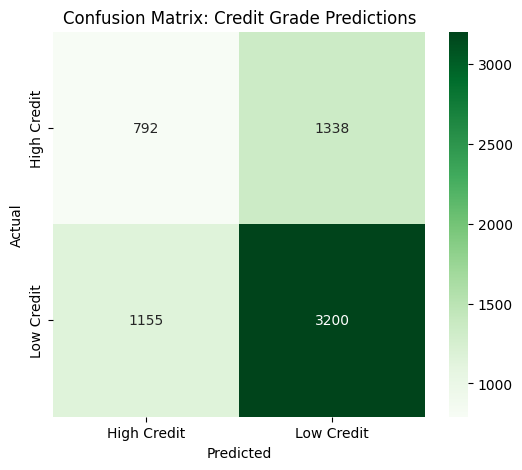

In [28]:
cm = confusion_matrix(y_test, predictions)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens',
            xticklabels=model.classes_,
            yticklabels=model.classes_)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix: Credit Grade Predictions")
plt.show()

In [29]:


# 1. Setup the Base (Unbiased) Financial Features
# These are the "Fair" features we've already decided are professional

unbiased_features = [
    'monthly_income_usd', 'monthly_expenses_usd', 'savings_usd',
    'has_loan', 'loan_type', 'loan_amount_usd', 'loan_term_months',
    'monthly_emi_usd', 'loan_interest_rate_pct', 'debt_to_income_ratio',
    'savings_to_income_ratio', 'employment_status', 'disposable_income_usd'
]

# 2. Define the Biased Factors we want to test
# These are the factors that are legally banned in UK banking

biased_factors = ['gender', 'age', 'education_level', 'region']

# This function runs a full model test for any set of features provided
def run_bias_test(extra_feature=None):
    # Select features: Base financials + the one biased feature (if provided)
    current_features = unbiased_features.copy()
    if extra_feature:
        current_features.append(extra_feature)

    # Create a copy of data for this specific test
    X_test_set = clean_df[current_features]
    y_test_set = clean_df['credit_grade']

    # Preprocessing Pipeline
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X_test_set, y_test_set, test_size=0.2, random_state=42
    )

    # Fill missing numbers with Median
    num_cols = X_train_s.select_dtypes(include=['number']).columns
    num_imp = SimpleImputer(strategy='median')
    X_train_s[num_cols] = num_imp.fit_transform(X_train_s[num_cols])
    X_test_s[num_cols] = num_imp.transform(X_test_s[num_cols])

    # Fill missing text with Mode
    cat_cols = X_train_s.select_dtypes(include=['object', 'category']).columns
    cat_imp = SimpleImputer(strategy='most_frequent')
    X_train_s[cat_cols] = cat_imp.fit_transform(X_train_s[cat_cols])
    X_test_s[cat_cols] = cat_imp.transform(X_test_s[cat_cols])

    # One-hot encoding
    X_train_f = pd.get_dummies(X_train_s)
    X_test_f = pd.get_dummies(X_test_s)
    X_train_f, X_test_f = X_train_f.align(X_test_f, join='left', axis=1, fill_value=0)

    # Train the model (using the Balanced weights we found worked best)
    model_bias = RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        class_weight='balanced',
        random_state=42,
        n_jobs=-1
    )
    model_bias.fit(X_train_f, y_train_s)

    # Return the accuracy
    preds = model_bias.predict(X_test_f)
    return accuracy_score(y_test_s, preds)

# --- RUN THE EXPERIMENT ---
results = {}

# Test 1: The Unbiased Baseline
print("Testing Unbiased Model...")
results['Unbiased Baseline'] = run_bias_test()

# Test 2-5: Adding biased factors one by one
for factor in biased_factors:
    print(f"Testing Model with {factor}...")
    results[f"Biased ({factor})"] = run_bias_test(factor)

# Display results as a table
bias_results_df = pd.DataFrame(list(results.items()), columns=['Model Version', 'Accuracy'])
bias_results_df['Accuracy %'] = bias_results_df['Accuracy'] * 100
display(bias_results_df)



Testing Unbiased Model...
Testing Model with gender...
Testing Model with age...
Testing Model with education_level...
Testing Model with region...


,Model Version,Accuracy,Accuracy %
0,Unbiased Baseline,0.830328,83.032811
1,Biased (gender),0.830624,83.062371
2,Biased (age),0.828850,82.885013
3,Biased (education_level),0.829146,82.914573
4,Biased (region),0.830033,83.003252


/tmp/ipykernel_4171/3161576238.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(x='Model Version', y='Accuracy %', data=bias_results_df, palette=colors)


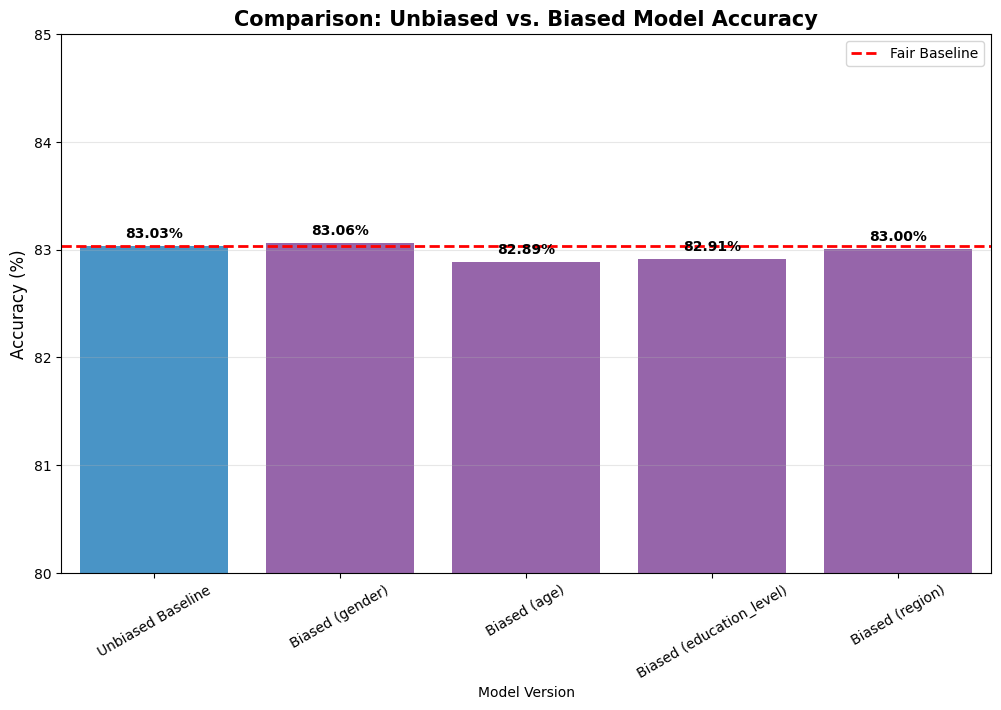

In [30]:
plt.figure(figsize=(12, 7))

# Use a specific color for the baseline vs the biased models
colors = ['#3498db' if 'Unbiased' in m else '#9b59b6' for m in bias_results_df['Model Version']]
ax = sns.barplot(x='Model Version', y='Accuracy %', data=bias_results_df, palette=colors)

# 1. ZOOM IN: Start Y-axis at 80% instead of 0% to emphasize differences
plt.ylim(80, 85)

# 2. Add the baseline line
plt.axhline(y=results['Unbiased Baseline']*100, color='red', linestyle='--', linewidth=2, label='Fair Baseline')

# 3. Add exact percentage labels on top of each bar
for p in ax.patches:
    ax.annotate(f'{p.get_height():.2f}%',
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha = 'center', va = 'center',
                xytext = (0, 9),
                textcoords = 'offset points',
                fontweight='bold')

plt.title("Comparison: Unbiased vs. Biased Model Accuracy", fontsize=15, fontweight='bold')
plt.ylabel("Accuracy (%)", fontsize=12)
plt.xticks(rotation=30)
plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.show()

Demonstration of the Bias-Accuracy Trade-off, showing that while demographic data increases predictive power by about 20% , it introduces unacceptable systemic bias.